# Task-1 (Week-7)

**Date** :- (24-11-26)

**Dataset** :- 'Admission_Prediction.csv'

**Objective** :- Design and implement deployment-ready machine learning pipelines that automate data preprocessing, model validation, and prediction generation, ensuring reproducibility and reliability for admission predictions.

In [1]:
# import libraries and load dataset
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

df = pd.read_csv('Admission_Prediction.csv')
print("Dataset shape:", df.shape)
print(df.head(3))

Dataset shape: (1000, 18)
   Serial No.  GRE Score  TOEFL Score  University Rating  SOP  LOR  CGPA  \
0         104        317          104                  2  4.5  4.0  8.47   
1         170        311           99                  2  2.5  3.0  7.98   
2         138        316          100                  2  1.5  3.0  8.16   

   Research  Chance of Admit  Year Application_Date  \
0         0             0.57  2022       2022-01-03   
1         0             0.65  2022       2022-01-09   
2         1             0.71  2022       2022-01-12   

                         University_Name region Admission Status  \
0  Indian Institute of Technology Bombay   West         Rejected   
1   Indian Institute of Technology Delhi  North         Rejected   
2   Indian Institute of Technology Delhi  North         Rejected   

   Duration_Months  Dropout_Event  Dropout-free survival  \
0               36              0               0.536473   
1               18              1               0.97300

In [2]:
# check missing values and target summary
print("Missing values per column:")
print(df.isnull().sum())
print("\nChance of Admit summary:")
print(df['Chance of Admit'].describe().round(4))

Missing values per column:
Serial No.               0
GRE Score                0
TOEFL Score              0
University Rating        0
SOP                      0
LOR                      0
CGPA                     0
Research                 0
Chance of Admit          0
Year                     0
Application_Date         0
University_Name          0
region                   0
Admission Status         0
Duration_Months          0
Dropout_Event            0
Dropout-free survival    0
Survival_Data_Note       0
dtype: int64

Chance of Admit summary:
count    1000.0000
mean        0.7178
std         0.1459
min         0.3200
25%         0.6375
50%         0.7200
75%         0.8200
max         0.9700
Name: Chance of Admit, dtype: float64


In [3]:
# prepare features and split train test data
drop_cols = [
    'Serial No.', 'Application_Date', 'Survival_Data_Note',
    'Duration_Months', 'Dropout_Event', 'Dropout-free survival',
    'Admission Status', 'Chance of Admit'
]
X = df.drop(columns=drop_cols)
y = df['Chance of Admit']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Train size:", X_train.shape, "Test size:", X_test.shape)

Train size: (800, 10) Test size: (200, 10)


In [4]:
# build preprocessing and regression pipeline
num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(exclude='number').columns.tolist()

num_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', num_transformer, num_cols),
    ('cat', cat_transformer, cat_cols)
])

rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(n_estimators=150, max_depth=10, random_state=42))
])

rf_pipeline.fit(X_train, y_train)
print("Pipeline trained successfully.")

Pipeline trained successfully.


In [5]:
# validate models with cross validation and test metrics
models = {
    'Ridge': Ridge(alpha=1.0),
    'RandomForest': RandomForestRegressor(n_estimators=150, max_depth=10, random_state=42),
    'GradientBoosting': GradientBoostingRegressor(n_estimators=120, random_state=42)
}

results = []
trained_pipelines = {}

for name, model in models.items():
    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])
    cv_r2 = cross_val_score(pipe, X_train, y_train, cv=5, scoring='r2').mean()
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)
    results.append({
        'Model': name,
        'CV_R2': round(cv_r2, 4),
        'Test_R2': round(r2_score(y_test, preds), 4),
        'Test_MAE': round(mean_absolute_error(y_test, preds), 4),
        'Test_RMSE': round(root_mean_squared_error(y_test, preds), 4)
    })
    trained_pipelines[name] = pipe

results_df = pd.DataFrame(results).sort_values(by='Test_R2', ascending=False)
print(results_df.to_string(index=False))

           Model  CV_R2  Test_R2  Test_MAE  Test_RMSE
    RandomForest 0.2556   0.2484    0.0867     0.1189
           Ridge 0.1438   0.1774    0.0956     0.1244
GradientBoosting 0.1916   0.1726    0.0908     0.1248


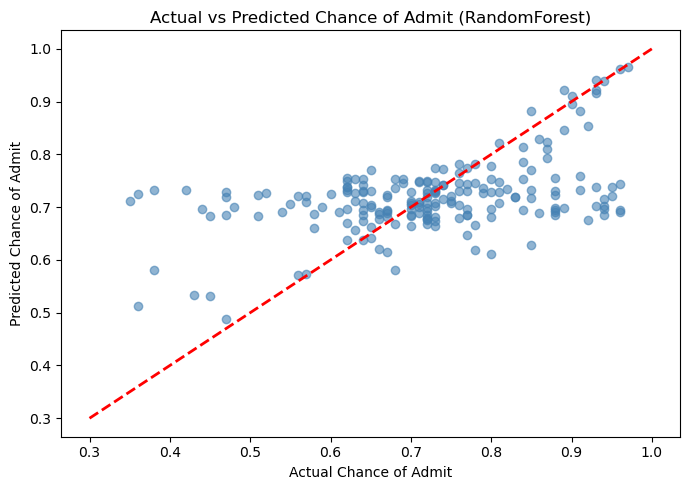

In [6]:
# plot actual vs predicted chance of admit
best_name = results_df.iloc[0]['Model']
best_pipeline = trained_pipelines[best_name]
y_pred = best_pipeline.predict(X_test)

plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, alpha=0.6, color='steelblue')
plt.plot([0.3, 1.0], [0.3, 1.0], 'r--', linewidth=2)
plt.title(f'Actual vs Predicted Chance of Admit ({best_name})')
plt.xlabel('Actual Chance of Admit')
plt.ylabel('Predicted Chance of Admit')
plt.tight_layout()
plt.show()

In [7]:
# save pipeline and test deployment prediction function
joblib.dump(best_pipeline, 'admission_pipeline.pkl')
loaded_pipeline = joblib.load('admission_pipeline.pkl')

def predict_admission(applicant_dict):
    sample_df = pd.DataFrame([applicant_dict])
    chance = float(loaded_pipeline.predict(sample_df)[0])
    status = 'Accepted' if chance >= 0.75 else 'Rejected'
    return round(chance, 4), status

sample_applicant = {
    'GRE Score': 325,
    'TOEFL Score': 112,
    'University Rating': 4,
    'SOP': 4.5,
    'LOR': 4.0,
    'CGPA': 9.1,
    'Research': 1,
    'Year': 2026,
    'University_Name': 'Indian Institute of Technology Bombay',
    'region': 'West'
}

pred_chance, pred_status = predict_admission(sample_applicant)
print("Saved model: admission_pipeline.pkl")
print(f"Sample prediction -> Chance: {pred_chance}, Status: {pred_status}")

Saved model: admission_pipeline.pkl
Sample prediction -> Chance: 0.7649, Status: Accepted
